# installing the required libraries which are not pre-installed in kaggle's environment

In [1]:
!pip install fireducks
!pip install contractions
!pip install optuna

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.4/7.4 MB 62.7 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 289.9/289.9 kB 9.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 118.3/118.3 kB 6.4 MB/s eta 0:00:00


# importing the required libraries

In [180]:
# Standard Libs

import os
import re
import string
import time
import pickle
import unicodedata

# Data Processing

import numpy as np
import fireducks.pandas as pd  
import contractions
import nltk
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer

# Plotting

import seaborn as sns
import matplotlib.pyplot as plt
from wordcloud import WordCloud

# Word Embeddings

from gensim.models import Word2Vec

# PyTorch Imports

import torch
import torch.nn as nn
import torch.optim as optim
from torch.nn.utils.rnn import pad_sequence
from torch.utils.data import DataLoader, TensorDataset, random_split

# Optimization

import optuna

# Evaluation

from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

In [179]:
nltk.download("punkt")
nltk.download('wordnet')
nltk.download('omw-1.4')

[nltk_data] Downloading package punkt to /usr/share/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package wordnet to /usr/share/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /usr/share/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


True

In [4]:
sns.set_theme()

In [5]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [6]:
f"using device {device}"

'using device cuda'

# loading the news headline dataset for sarcasm detection

In [7]:
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

/kaggle/input/news-headlines-dataset-for-sarcasm-detection/Sarcasm_Headlines_Dataset_v2.json
/kaggle/input/news-headlines-dataset-for-sarcasm-detection/Sarcasm_Headlines_Dataset.json


In [8]:
df = pd.read_json("/kaggle/input/news-headlines-dataset-for-sarcasm-detection/Sarcasm_Headlines_Dataset_v2.json", lines  = True)

In [9]:
df

,is_sarcastic,headline,article_link
0,1,thirtysomething scientists unveil doomsday clo...,https://www.theonion.com/thirtysomething-scien...
1,0,dem rep. totally nails why congress is falling...,https://www.huffingtonpost.com/entry/donna-edw...
2,0,eat your veggies: 9 deliciously different recipes,https://www.huffingtonpost.com/entry/eat-your-...
3,1,inclement weather prevents liar from getting t...,https://local.theonion.com/inclement-weather-p...
4,1,mother comes pretty close to using word 'strea...,https://www.theonion.com/mother-comes-pretty-c...
...,...,...,...
28614,1,jews to celebrate rosh hashasha or something,https://www.theonion.com/jews-to-celebrate-ros...
28615,1,internal affairs investigator disappointed con...,https://local.theonion.com/internal-affairs-in...
28616,0,the most beautiful acceptance speech this week...,https://www.huffingtonpost.com/entry/andrew-ah...
28617,1,mars probe destroyed by orbiting spielberg-gat...,https://www.theonion.com/mars-probe-destroyed-...


In [10]:
df = df[["headline", "is_sarcastic"]]

In [11]:
df

,headline,is_sarcastic
0,thirtysomething scientists unveil doomsday clo...,1
1,dem rep. totally nails why congress is falling...,0
2,eat your veggies: 9 deliciously different recipes,0
3,inclement weather prevents liar from getting t...,1
4,mother comes pretty close to using word 'strea...,1
...,...,...
28614,jews to celebrate rosh hashasha or something,1
28615,internal affairs investigator disappointed con...,1
28616,the most beautiful acceptance speech this week...,0
28617,mars probe destroyed by orbiting spielberg-gat...,1


In [12]:
df.isnull().sum()

headline        0
is_sarcastic    0
dtype: int64

In [13]:
df.info()

<class 'fireducks.pandas.frame.DataFrame'>
RangeIndex: 28619 entries, 0 to 28618
Data columns (total 2 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   headline      28619 non-null  object
 1   is_sarcastic  28619 non-null  int64 
dtypes: int64(1), object(1)
memory usage: 447.2+ KB


**If we plot the graphs using a FireDucks DataFrame, we will get the following error:**

`RuntimeError: AttributeError: Can only use .cat accessor with a 'category' dtype.`

**Why does this happen?**

Because we are using a backend (likely FireDucks for accelerated Pandas) that tries to optimize operations, but Seaborn expects standard Pandas DataFrame behavior.

So, just for plotting purposes, we need to convert our FireDucks DataFrame into a standard Pandas DataFrame."


# checking if our data is imbalanced

In [14]:
df_pd = df.to_pandas()

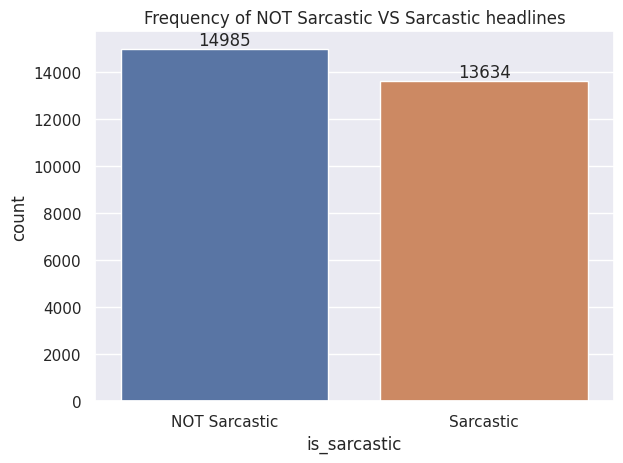

In [15]:
ax = sns.countplot(data = df_pd, x = "is_sarcastic")

ax.set_xticklabels(['NOT Sarcastic', 'Sarcastic'])

for p in ax.patches:
    count = int(p.get_height())
    ax.annotate(
        f'{count}',        
        (p.get_x() + p.get_width() / 2., p.get_height()),
        ha = "center",
        va = "bottom"
    )

plt.title("Frequency of NOT Sarcastic VS Sarcastic headlines")
plt.tight_layout()
plt.show()

# cleaning the dataset

In [16]:
lemmatizer = WordNetLemmatizer()

In [17]:
allowed_characters = allowed_characters = string.ascii_letters + string.digits + string.punctuation + " "

def unicodeToAscii(text: str) -> str:
    return "".join(
        c for c in unicodedata.normalize("NFD", text)
        if unicodedata.category(c) != "Mn"
        and c in allowed_characters
    )

In [18]:
def handle_special_cases(text: str) -> str:
    def round_currency(match):
        number = float(match.group(1))
        return f"{round(number)} dollars"
        
    text = re.sub(r'(?<=\d),(?=\d)', '', text)
    
    text = re.sub(r'\$(\d+\.\d+)', round_currency, text)
    
    text = re.sub(r'\$(\d+)(?!\.\d)', r'\1 dollars', text)
    
    text = re.sub(r'(\d+)%', r'\1 percent', text)
    
    def round_decimal(match):
        number = float(match.group(0))
        return str(round(number))

    text = re.sub(r'(?<![\d$])\d+\.\d+(?![\d%])', round_decimal, text)

    return text

In [19]:
expanded_contractions = {
    "sept.": "september",
    "u.s.": "unitedstates",
    "nyc": "newyorkcity",
    "u.k.": "unitedkingdom",
    "b.c.": "beforechrist",
    "c'mon": "come on",
    "gov't": "government",
    "don'ts": "do not",
    "gimme": "give me"
}

apostrophe_pattern = r"\b\w+'\w+\b"

def expand_contractions(text: str) -> str:    
    for contraction, expanded in expanded_contractions.items():
        if contraction in text:
            sorted_keys = sorted(expanded_contractions.keys(), key=len, reverse=True)
            
            pattern_parts = []
            
            for key in sorted_keys:
                if key.isalpha() and len(key) <= 2:
                    pattern_parts.append(rf'\b{re.escape(key)}\b')
                else:
                    pattern_parts.append(re.escape(key))
        
            pattern = re.compile('|'.join(pattern_parts), flags=re.IGNORECASE)
            
            text = pattern.sub(lambda match: expanded_contractions[match.group(0).lower()], text)
            
    matches = re.findall(apostrophe_pattern, text)

    if matches:
        for word in matches:
            expanded_word = contractions.fix(word)
            
            if word == expanded_word:
                expanded_word = re.sub(r"'s\b", " has", word)
                
            text = text.replace(word, expanded_word)
        
    return text

In [20]:
def remove_punctuations(text: str) -> str:
    return re.sub(f"[{re.escape(string.punctuation)}]", " ", text)

In [21]:
def remove_extra_spaces(text: str) -> str:
    return re.sub(r'\s+', ' ', text)

In [22]:
words_being_lemmatized_wrongly = {
    "has": "has",
    "us": "us"  
}

def lemmatize_text(text: str) -> str:
    lemmatized_words = []
    for word in word_tokenize(text):
        if word in words_being_lemmatized_wrongly:
            lemmatized_words.append(words_being_lemmatized_wrongly[word])
        else:
            lemmatized_words.append(lemmatizer.lemmatize(word))
    return " ".join(lemmatized_words)

In [23]:
def clean_text(text: str) -> str:
    text = text.lower()
    text = unicodeToAscii(text)
    text = handle_special_cases(text)
    text = expand_contractions(text)
    text = remove_punctuations(text)
    text = remove_extra_spaces(text)
    text = lemmatize_text(text)
    return text.strip()

## testing the final clean function

In [24]:
clean_text("I've been to São Paulo, and it isn't the kind of city you'd forget — it's full of life, color, and chaos! 😊✨")

'i have been to sao paulo and it is not the kind of city you would forget it is full of life color and chaos'

## applying the final clean function to the dataset

In [25]:
df["headline"] = df["headline"].apply(clean_text)

In [26]:
df

,headline,is_sarcastic
0,thirtysomething scientist unveil doomsday cloc...,1
1,dem rep totally nail why congress is falling s...,0
2,eat your veggie 9 deliciously different recipe,0
3,inclement weather prevents liar from getting t...,1
4,mother come pretty close to using word streami...,1
...,...,...
28614,jew to celebrate rosh hashasha or something,1
28615,internal affair investigator disappointed cons...,1
28616,the most beautiful acceptance speech this week...,0
28617,mar probe destroyed by orbiting spielberg gate...,1


In [27]:
df = df[df["headline"].str.split().apply(len) >= 3]

In [28]:
df = df[~df.duplicated()].reset_index(drop = True)

In [29]:
df

,headline,is_sarcastic
0,thirtysomething scientist unveil doomsday cloc...,1
1,dem rep totally nail why congress is falling s...,0
2,eat your veggie 9 deliciously different recipe,0
3,inclement weather prevents liar from getting t...,1
4,mother come pretty close to using word streami...,1
...,...,...
28402,jew to celebrate rosh hashasha or something,1
28403,internal affair investigator disappointed cons...,1
28404,the most beautiful acceptance speech this week...,0
28405,mar probe destroyed by orbiting spielberg gate...,1


# Data Analysis

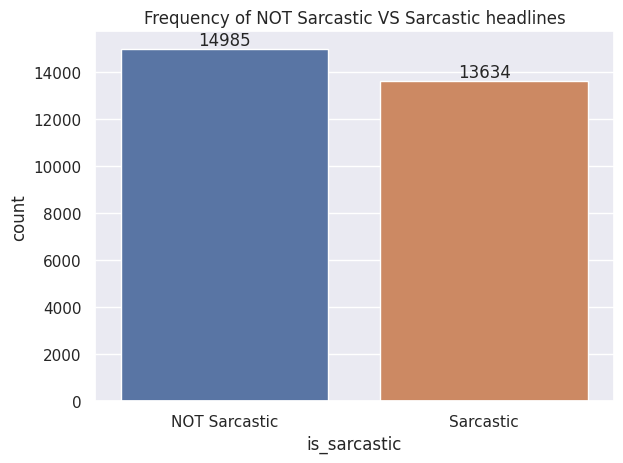

In [30]:
ax = sns.countplot(data = df_pd, x = "is_sarcastic")

ax.set_xticklabels(['NOT Sarcastic', 'Sarcastic'])

for p in ax.patches:
    count = int(p.get_height())
    ax.annotate(
        f'{count}',        
        (p.get_x() + p.get_width() / 2., p.get_height()),
        ha = "center",
        va = "bottom"
    )

plt.title("Frequency of NOT Sarcastic VS Sarcastic headlines")
plt.tight_layout()
plt.show()

In [31]:
def plot_wordcloud(label: int):
    headlines = " ".join(df_pd[df_pd["is_sarcastic"] == label]["headline"])
    
    headlines_wordcloud = WordCloud(width = 1600, height = 800).generate(headlines)

    if label == 0:
        plt.title("Most Frequent Words in Non-Sarcastic Headlines")
        
    if label == 1:
        plt.title("Most Frequent Words in Sarcastic Headlines")
        
    plt.imshow(headlines_wordcloud)

    plt.axis("off")
    plt.tight_layout()
    plt.show()

In [32]:
def plot_top_n_most_frequent_words(n: int, label: int):
    df_pd = df.to_pandas()
    
    headlines_words_frequency = {}

    for headline in df_pd[df_pd["is_sarcastic"] == label]["headline"]:
        for word in headline.split():
            if word in headlines_words_frequency:
                headlines_words_frequency[word] += 1
            else:
                headlines_words_frequency[word] = 1
                
    headlines_words_frequency_df = pd.DataFrame(
        dict(sorted(headlines_words_frequency.items(), key=lambda item: item[1], reverse=True)[:n]).items(),
        columns=["word", "frequency"]
    )
    
    headlines_words_frequency_df_pd = (
        headlines_words_frequency_df.to_pandas()
        if hasattr(headlines_words_frequency_df, "to_pandas")
        else headlines_words_frequency_df
    )
    
    sns.barplot(data=headlines_words_frequency_df_pd, x="frequency", y="word")

    for index, row in headlines_words_frequency_df_pd.iterrows():
        plt.text(row['frequency'] + 0.5, index, str(row['frequency']), va='center')

    plt.title(f"Top {n} Most Frequent Words in {'Sarcastic' if label == 1 else 'Non-Sarcastic'} Headlines")
    plt.xlabel('Frequency')
    plt.ylabel('Word')
    plt.tight_layout()
    plt.show()

In [33]:
def plot_words_in_each_headline_histogram(label: int):
    df_pd = df.to_pandas()
    
    sns.histplot(df_pd[df_pd["is_sarcastic"] == label]["headline"].str.split().apply(len))
    if label == 0:
        plt.title(f"Words in each Non-Sarcastic Headline Histogram")
    if label == 1:
        plt.title(f"Words in each Sarcastic Headline Histogram")

    plt.xlabel("Frequency of Words in each headline")
    plt.ylabel("Frequency of headlines")
    plt.tight_layout()
    plt.show()

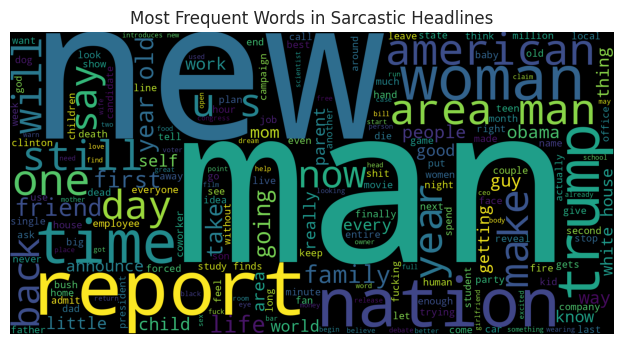

In [34]:
plot_wordcloud(1)

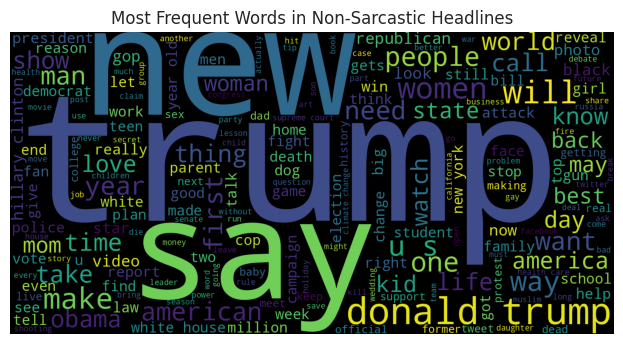

In [35]:
plot_wordcloud(0)

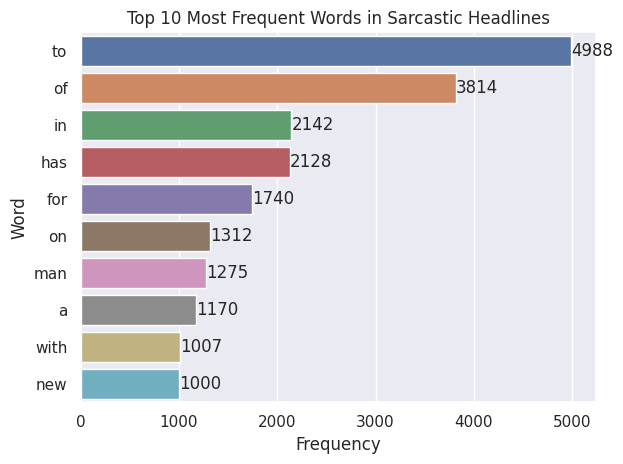

In [36]:
plot_top_n_most_frequent_words(10, 1)

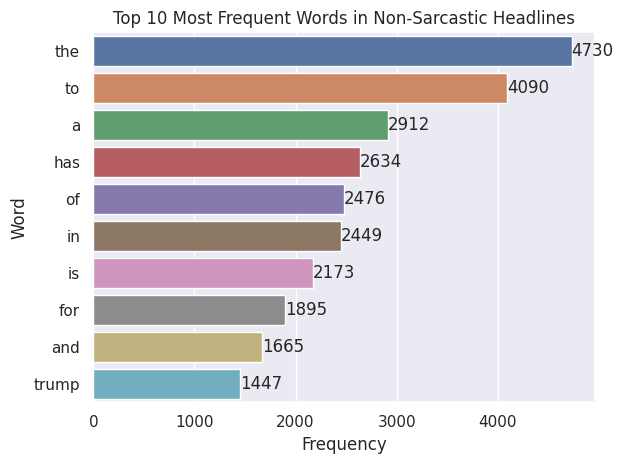

In [37]:
plot_top_n_most_frequent_words(10, 0)

/usr/local/lib/python3.11/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


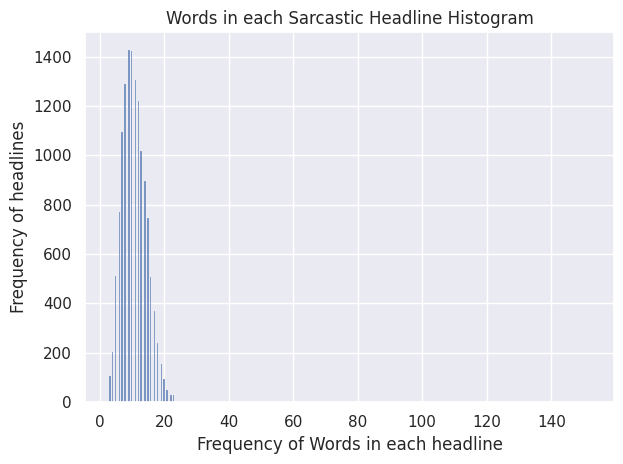

In [38]:
plot_words_in_each_headline_histogram(1)

/usr/local/lib/python3.11/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


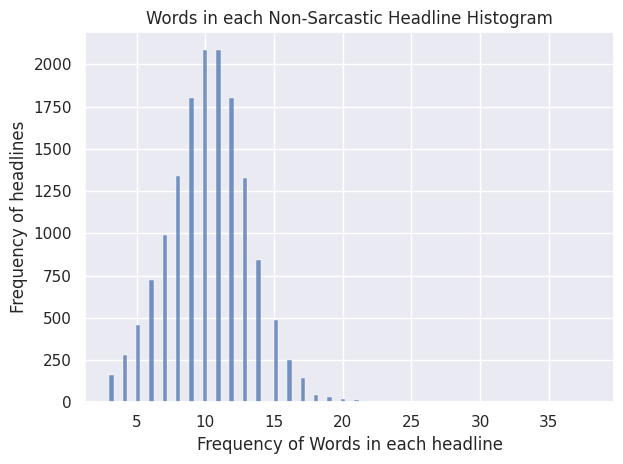

In [39]:
plot_words_in_each_headline_histogram(0)

# preparing our data for the deep learning model

## tokenizing each sentence

In [40]:
tokenized_sentences = []

for headline in df["headline"]:
    tokenized_sentences.append(headline.split())

In [41]:
tokenized_sentences[:3]

[['thirtysomething',
  'scientist',
  'unveil',
  'doomsday',
  'clock',
  'of',
  'hair',
  'loss'],
 ['dem',
  'rep',
  'totally',
  'nail',
  'why',
  'congress',
  'is',
  'falling',
  'short',
  'on',
  'gender',
  'racial',
  'equality'],
 ['eat', 'your', 'veggie', '9', 'deliciously', 'different', 'recipe']]

In [42]:
lengths = [len(tokenized_sentence) for tokenized_sentence in tokenized_sentences]

f"95% of our sentences' length is {int(np.percentile(lengths, 95))} so we setting the max length as 20"

"95% of our sentences' length is 16 so we setting the max length as 20"

In [43]:
MAX_LENGTH = 20
EMBEDDING_DIM = 300

## defining our word2vec model from which we will convert our words into vectors

In [44]:
w2v_model = Word2Vec(sentences = tokenized_sentences,
                     vector_size = EMBEDDING_DIM,
                     window = 10,
                     min_count = 1,
                     sg = 1,
                     negative = 10,
                     epochs = 20)

## saving the word2vec model to load later in production

In [337]:
w2v_model.save("word2vec.model")

## the below code is used to load the saved word2vec model in production 

In [46]:
# w2v_model = Word2Vec.load("word2vec.model")

## creating the vocabulary from my word2vec model to give each word an index

In [47]:
vocabulary = w2v_model.wv.index_to_key

In [48]:
f"there are total {len(vocabulary)} unique words in our dataset"

'there are total 23226 unique words in our dataset'

## creating the word_to_index dictionary so i could map each word to its index, allowing me to convert sentences into indexed form to feed into my neural net with 2 predefined mappings
## - 0 for padding if a sentence is shorter than the max length i defined that is 20
## - 1 for unknown words which will come in production by users

In [49]:
word_to_index = {"<PAD>": 0, "<UNK>": 1}

In [50]:
for i, word in enumerate(w2v_model.wv.index_to_key):
    word_to_index[word] = i + 2

In [51]:
len(word_to_index)

23228

## saving the word_to_index dictionary to use later in production

In [342]:
# with open("word_to_index.pkl", "wb") as f:
#     pickle.dump(word_to_index, f)

## the below code is used to load the word_to_index dictionary in production

In [53]:
# with open("word_to_index.pkl", "rb") as f:
#     word_to_index = pickle.load(f)

## converting each tokenized sentence into indexed sentence to feed into my neural net as a neural net doesnt take alphabets

In [54]:
def tokenized_sentence_to_indexed_sentence(tokenized_sentence):
    indexed_sentence = []
    
    for word in tokenized_sentence:
        if word in word_to_index:
            indexed_sentence.append(word_to_index[word])
        else:
            indexed_sentence.append(word_to_index["<UNK>"])
            
    return indexed_sentence

In [55]:
indexed_sentences = [tokenized_sentence_to_indexed_sentence(tokenized_sentence) for tokenized_sentence in tokenized_sentences]

In [223]:
indexed_sentences[:3]

[[13349, 344, 3058, 6649, 2263, 3, 680, 1129],
 [6724, 1576, 814, 1782, 55, 276, 9, 1907, 982, 10, 1428, 1978, 1837],
 [940, 42, 9870, 321, 23171, 671, 1210]]

## a neural net requires every input to be of the same length. so for the sake of that i am making the length of each sentence same which is 20 as defined above as MAX_LENGTH

In [224]:
def pad_sequence(seq, pad_value=0):
    return [pad_value] * max(0, MAX_LENGTH - len(seq)) + seq[:MAX_LENGTH]

In [57]:
padded_indexed_sentences = torch.tensor([pad_sequence(indexed_sentence) for indexed_sentence in indexed_sentences])

In [58]:
padded_indexed_sentences.shape

torch.Size([28407, 20])

In [59]:
padded_indexed_sentences[:3]

tensor([[    0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
             0,     0, 13349,   344,  3058,  6649,  2263,     3,   680,  1129],
        [    0,     0,     0,     0,     0,     0,     0,  6724,  1576,   814,
          1782,    55,   276,     9,  1907,   982,    10,  1428,  1978,  1837],
        [    0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
             0,     0,     0,   940,    42,  9870,   321, 23171,   671,  1210]])

## preparing the embedding matrix which will be passed in embedding layer of my neural net as i am using pretrained embeddings which i just prepared above using word2vec

In [60]:
embedding_matrix = np.zeros((len(word_to_index), EMBEDDING_DIM))

In [61]:
embedding_matrix.shape

(23228, 300)

In [62]:
for word, index in word_to_index.items():
    if word == "<PAD>":
        embedding_matrix[index] = torch.zeros(EMBEDDING_DIM)
        
    elif word == "<UNK>":
        embedding_matrix[index] = torch.randn(EMBEDDING_DIM)
    
    else:
        embedding_matrix[index] = torch.tensor(w2v_model.wv[word])

## saving the embedding matrix

In [63]:
with open('embedding_matrix.pkl', 'wb') as f:
    pickle.dump(embedding_matrix, f)

## the below code is used to load the embedding matrix in production

In [341]:
# with open('embedding_matrix.pkl', 'wb') as f:
#     pickle.dump(embedding_matrix, f)

# converting our padded_indexed_sequences and their respective array of labels into tensors using TensorDataset class provided by pytorch for efficient training

In [65]:
dataset = TensorDataset(padded_indexed_sentences, torch.tensor(df["is_sarcastic"].values, dtype = torch.float))

In [66]:
total_size = len(dataset)

In [67]:
total_size

28407

# splitting our dataset into training (80%), validation (10%), and testing (10%)

In [68]:
train_size = int(0.8 * total_size)
val_size = int(0.1 * total_size)
test_size = total_size - train_size - val_size

In [69]:
train_dataset, val_dataset, test_dataset = random_split(dataset, [train_size, val_size, test_size])

In [70]:
f"there are {len(train_dataset)} samples in our training data, {len(val_dataset)} in our validation data, and {len(test_dataset)} in our testing dataset"

'there are 22725 samples in our training data, 2840 in our validation data, and 2842 in our testing dataset'

# you may ignore the below architecture of the RNN, basically i tried to create a really complex model for best accuracies but it was a dumb decision as my dataset is too small, no need of this much complex model so i never used this model

In [72]:
# class HeadlineSarcasmClassifier(nn.Module):
#     def __init__(
#         self,
        
#         embedding_matrix,
        
#         lstm_hidden_dim,
#         lstm_bidirectional,
#         num_lstm_layers,
#         lstm_dropout_rate,
        
#         gru_hidden_dim,
#         gru_bidirectional,
#         num_gru_layers,
#         gru_dropout_rate,
    
#         layers_size,
#         dropout_rates):
#         super(HeadlineSarcasmClassifier, self).__init__()

#         vocab_size, EMBEDDING_DIM = embedding_matrix.shape

#         self.embedding = nn.Embedding(num_embeddings = vocab_size, EMBEDDING_DIM = EMBEDDING_DIM)
#         self.embedding.weight = nn.Parameter(torch.tensor(embedding_matrix, dtype = torch.float32))
#         self.embedding.weight.requires_grad = False

#         self.lstm = nn.LSTM(
#             input_size = EMBEDDING_DIM,
#             hidden_size = lstm_hidden_dim,
#             batch_first = True,
#             bidirectional = lstm_bidirectional,
#             num_layers = num_lstm_layers,
#             dropout = lstm_dropout_rate if num_lstm_layers > 1 else 0)

#         lstm_output_dim = lstm_hidden_dim * (2 if lstm_bidirectional else 1)

#         self.batchnorm_lstm = nn.BatchNorm1d(lstm_output_dim)
#         self.dropout_lstm = nn.Dropout(lstm_dropout_rate)

#         self.gru = nn.GRU(
#             input_size = lstm_output_dim,
#             hidden_size = gru_hidden_dim,
#             batch_first = True,
#             bidirectional = gru_bidirectional,
#             num_layers = num_gru_layers,
#             dropout = gru_dropout_rate if num_gru_layers > 1 else 0)

#         gru_output_dim = gru_hidden_dim * (2 if gru_bidirectional else 1)

#         self.batchnorm_gru = nn.BatchNorm1d(gru_output_dim)
#         self.dropout_gru = nn.Dropout(gru_dropout_rate)

#         linear_layer_input_size = gru_output_dim

#         linear_layers = []

#         for hidden_size, dropout_rate in zip(layers_size, dropout_rates):
#             linear_layers.append(nn.Linear(in_features = linear_layer_input_size, out_features = hidden_size))
#             linear_layers.append(nn.BatchNorm1d(hidden_size))
#             linear_layers.append(nn.ReLU())
#             linear_layers.append(nn.Dropout(dropout_rate))
            
#             linear_layer_input_size = hidden_size

#         linear_layers.append(nn.Linear(linear_layer_input_size, 1))

#         self.linear_layers = nn.Sequential(*linear_layers)

#         self.sigmoid = nn.Sigmoid()

#     def forward(self, x):
#         embeddings = self.embedding(x)
        
#         lstm_output, _ = self.lstm(embeddings)
#         lstm_output = lstm_output[:, -1, :]
#         lstm_output = self.batchnorm_lstm(lstm_output)
#         lstm_output = self.dropout_lstm(lstm_output)

#         gru_input = lstm_output.unsqueeze(1) 
#         gru_output, _ = self.gru(gru_input)
#         gru_output = gru_output[:, -1, :]
#         gru_output = self.batchnorm_gru(gru_output)
#         gru_output = self.dropout_gru(gru_output)

#         out = self.linear_layers(gru_output)
#         return self.sigmoid(out).squeeze(1)

# def objective(trial):
#     batch_size = trial.suggest_categorical("batch_size", [32, 64, 128])

#     lstm_hidden_dim = trial.suggest_int(f"lstm_hidden_dim", 32, 512)
#     lstm_bidirectional = trial.suggest_categorical(f"lstm_bidirectional", [True, False])
#     num_lstm_layers = trial.suggest_int(f"num_lstm_layers", 1, 5)
#     lstm_dropout_rate = trial.suggest_float(f"lstm_dropout_rate", 0.1, 0.5)

#     gru_hidden_dim = trial.suggest_int(f"gru_hidden_dim", 32, 512)
#     gru_bidirectional = trial.suggest_categorical(f"gru_bidirectional", [True, False])
#     num_gru_layers = trial.suggest_int(f"num_gru_layers", 1, 5)
#     gru_dropout_rate = trial.suggest_float(f"gru_dropout_rate", 0.1, 0.5)
    
#     number_of_hidden_linear_layers = trial.suggest_int("number_of_hidden_layers", 1, 5)

#     layers_size = []
    
#     dropout_rates = []

#     for i in range(number_of_hidden_linear_layers):
#         layer_size = trial.suggest_int(f"layer_size{i}", 32, 512)
#         layers_size.append(layer_size)

#         dropout_rate = trial.suggest_float(f"dropout_rate{i}", 0.1, 0.5)
#         dropout_rates.append(dropout_rate)
        
#     optimizer_name = trial.suggest_categorical("optimizer_name", ["Adam", "AdamW", "SGD", "RMSprop"])
    
#     lr = trial.suggest_float("lr", 1e-5, 1e-1)
    
#     weight_decay = trial.suggest_float("weight_decay", 1e-5, 1e-1)

#     train_loader = DataLoader(train_dataset, batch_size = batch_size, shuffle = True)
#     val_loader = DataLoader(val_dataset, batch_size = batch_size, shuffle = False)

#     headline_sarcasm_classifier = HeadlineSarcasmClassifier(
#         embedding_matrix = embedding_matrix,
        
#         lstm_hidden_dim = lstm_hidden_dim,
#         lstm_bidirectional = lstm_bidirectional,
#         num_lstm_layers = num_lstm_layers,
#         lstm_dropout_rate = lstm_dropout_rate,
    
#         gru_hidden_dim = gru_hidden_dim,
#         gru_bidirectional = gru_bidirectional,
#         num_gru_layers = num_gru_layers,
#         gru_dropout_rate = gru_dropout_rate,
    
#         layers_size = layers_size,
#         dropout_rates = dropout_rates).to(device)

#     if optimizer_name == "Adam":
#         optimizer = optim.Adam(headline_sarcasm_classifier.parameters(), lr = lr, weight_decay = weight_decay)
#     elif optimizer_name == "SGD":
#         optimizer = optim.SGD(headline_sarcasm_classifier.parameters(), lr = lr, weight_decay = weight_decay)
#     elif optimizer_name == "AdamW":
#         optimizer = optim.AdamW(headline_sarcasm_classifier.parameters(), lr = lr, weight_decay = weight_decay)
#     else:
#         optimizer = optim.RMSprop(headline_sarcasm_classifier.parameters(), lr = lr, weight_decay = weight_decay)

#     headline_sarcasm_classifier.train()
    
#     for epoch in range(5):
#         for inputs_batch, labels_batch in train_loader:
#             inputs_batch, labels_batch = inputs_batch.to(device), labels_batch.to(device)
            
#             optimizer.zero_grad()
            
#             outputs = headline_sarcasm_classifier(inputs_batch)
    
#             loss = criterion(outputs, labels_batch)

#             loss.backward()

#             optimizer.step()
    
#     headline_sarcasm_classifier.eval()

#     correct = 0
#     total = 0

#     with torch.no_grad():
#         for inputs_batch, labels_batch in val_loader:
#                 inputs_batch, labels_batch = inputs_batch.to(device), labels_batch.to(device)
                
#                 outputs = headline_sarcasm_classifier(inputs_batch)

#                 outputs = torch.round(outputs)
            
#                 correct += (outputs == labels_batch).sum().item()

#                 total += labels_batch.size(0)

#     return correct / total

> **Note:**  
> In the above code, the hyperparameter search space is extremely large, allowing for approximately **3.24 × 10³²** unique RNN model configurations. This complexity makes exhaustive tuning impractical without access to significant computational resources (e.g., a large number of GPUs).  
> 
> To ensure efficient experimentation and faster training, I will use a simplified model with a reduced number of tunable parameters.

# defining the functions which will be used during the training

In [117]:
def plot_metrics(train_accuracies, train_losses, val_accuracies, val_losses):
    epochs = range(1, len(train_accuracies) + 1)
    
    fig, axes = plt.subplots(1, 2, figsize=(16, 7))
    
    axes[0].plot(epochs, train_accuracies, label='Training Accuracy', marker='o', color='green')
    axes[0].plot(epochs, train_losses, label='Training Loss', marker='x', color='red')
    axes[0].set_title('Training Accuracy and Loss')
    axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel('Value')
    axes[0].legend()
    axes[0].grid(True)
    
    axes[1].plot(epochs, val_accuracies, label='Validation Accuracy', marker='o', color='green')
    axes[1].plot(epochs, val_losses, label='Validation Loss', marker='x', color='red')
    axes[1].set_title('Validation Accuracy and Loss')
    axes[1].set_xlabel('Epoch')
    axes[1].set_ylabel('Value')
    axes[1].legend()
    axes[1].grid(True)
    
    plt.tight_layout()
    plt.show()

In [161]:
class EarlyStopping:
    def __init__(self, patience = 3, min_delta = 0.0, path = "best_model.pt", verbose = True):
        self.patience = patience
        self.min_delta = min_delta
        self.path = path
        self.verbose = verbose
        self.counter = 0
        self.best_score = None
        self.early_stop = False
        self.best_model_weights = None

    def __call__(self, val_loss, model):
        score = -val_loss

        if self.best_score is None:
            self.best_score = score
            self.save_checkpoint(model)
        elif score < self.best_score + self.min_delta:
            self.counter += 1
            if self.verbose:
                print(f"\nEarlystopping counter: {self.counter}/{self.patience}")
            if self.counter == self.patience:
                self.early_stop = True
        else:
            self.best_score = score
            self.save_checkpoint(model)
            self.counter = 0

    def save_checkpoint(self, model):
        if self.verbose:
            print(f"\nValidation loss improved than before. Saving model to {self.path}")
        torch.save(model.state_dict(), self.path)

In [165]:
def train(model, epochs, train_loader, validation_loader, optimizer, criterion, early_stopper, device):
    print("Training started")
    
    training_starting_time = time.time()

    training_accuracies, training_losses, validation_accuracies, validation_losses = [], [], [], []

    for epoch in range(1, EPOCHS + 1):
        model.train()
        epoch_starting_time = time.time()
        
        print(f"\nEpoch # {epoch}\n")
        
        epoch_total_training_loss, epoch_training_predictions, epoch_training_labels = 0., [], []
        epoch_total_validation_loss, epoch_validation_predictions, epoch_validation_labels = 0., [], []
        
        for batch_no, (training_inputs_batch, training_labels_batch) in enumerate(train_loader):
            training_inputs_batch, training_labels_batch = training_inputs_batch.to(device), training_labels_batch.float().to(device)
            
            optimizer.zero_grad()
            
            training_logits, _ = model(training_inputs_batch)
            
            batch_training_loss = criterion(training_logits, training_labels_batch)
    
            epoch_total_training_loss += batch_training_loss.item()
    
            batch_training_loss.backward()
    
            optimizer.step()
            
            training_predictions = torch.round(torch.sigmoid(training_logits))
    
            epoch_training_predictions.extend(training_predictions)
            epoch_training_labels.extend(training_labels_batch)
    
            if (batch_no + 1) % 30 == 0:
                    print(f"Batch # {batch_no + 1} / {len(train_loader)}, Loss: {batch_training_loss:.3f}")
    
        model.eval()
        
        with torch.no_grad():
            for validation_inputs_batch, validation_labels_batch in val_loader:
                validation_inputs_batch, validation_labels_batch = validation_inputs_batch.to(device), validation_labels_batch.float().to(device)
                
                validation_logits, _ = model(validation_inputs_batch)
                
                batch_validation_loss = criterion(validation_logits, validation_labels_batch)
        
                epoch_total_validation_loss += batch_validation_loss.item()
                
                validation_predictions = torch.round(torch.sigmoid(validation_logits))
        
                epoch_validation_predictions.extend(validation_predictions)
                epoch_validation_labels.extend(validation_labels_batch)
    
        training_accuracy = ((torch.tensor(epoch_training_predictions) == torch.tensor(epoch_training_labels)).sum().item()) / len(epoch_training_labels)
        training_loss = epoch_total_training_loss / len(train_loader)
        
        validation_accuracy = ((torch.tensor(epoch_validation_predictions) == torch.tensor(epoch_validation_labels)).sum().item()) / len(epoch_validation_labels)
        validation_loss = epoch_total_validation_loss / len(val_loader)
    
        training_accuracies.append(training_accuracy)
        training_losses.append(training_loss)
        
        validation_accuracies.append(validation_accuracy)
        validation_losses.append(validation_loss)

        early_stopper(validation_loss, model)

        if early_stopper.early_stop:
            print(f"\nEarly stopping triggered, Training stopped because validation loss was increasing instead of decreasing.\n")
            break
    
        print(f"\nTraining Accuracy: {training_accuracy:.3f}, Training Loss: {training_loss:.3f}, Validation Accuracy: {validation_accuracy:.3f}, Validation Loss: {validation_loss:.3f}")

        print(f"\nEpoch Duration: {int(time.time() - epoch_starting_time)} seconds")

    training_ending_time = time.time()

    training_elapsed_time = training_ending_time - training_starting_time

    training_elapsed_time_minutes = training_elapsed_time // 60

    print(f"Training completed in {int(training_elapsed_time_minutes)} minutes and {int(training_elapsed_time - (training_elapsed_time_minutes * 60))} seconds")
    
    print(f"\nTraining ended")

    return training_accuracies, training_losses, validation_accuracies, validation_losses

In [119]:
criterion = nn.BCEWithLogitsLoss()

# defining the architeture of my rnn model

In [104]:
class HeadlineSarcasmClassifierAndDetector(nn.Module):
    def __init__(self, embedding_matrix, hidden_dim):
        super().__init__()
        vocab_size, embedding_dim = embedding_matrix.shape

        self.embedding = nn.Embedding.from_pretrained(torch.tensor(embedding_matrix, dtype = torch.float32), freeze = True)
        
        self.lstm = nn.LSTM(embedding_dim, hidden_dim, batch_first = True, bidirectional = True)
        
        self.gru = nn.GRU(hidden_dim * 2, hidden_dim, batch_first = True, bidirectional = True)

        self.attention = nn.Linear(hidden_dim * 2, 1)
        
        self.fc = nn.Linear(hidden_dim * 2, 1) 

    def forward(self, x):
        embeddings = self.embedding(x)
        
        lstm_output, _ = self.lstm(embeddings)
        
        gru_output, _ = self.gru(lstm_output)
        
        attention_scores = self.attention(gru_output).squeeze(-1)
        attention_weights = torch.softmax(attention_scores, dim = 1)

        context = torch.bmm(attention_weights.unsqueeze(1), gru_output).squeeze(1)
        
        logits = self.fc(context)
        outputs = logits.squeeze(1)

        return outputs, attention_weights

# i will be hyper-parameter tuning some parameters of my model using optuna to get the best accuracy with the perfect parameters 

In [106]:
def objective(trial):
    batch_size = trial.suggest_categorical("batch_size", [32, 64, 128])

    hidden_dim = trial.suggest_int("hidden_dim", 32, 512)
    
    optimizer_name = trial.suggest_categorical("optimizer_name", ["Adam", "AdamW", "SGD", "RMSprop"])
    
    lr = trial.suggest_float("lr", 1e-5, 1e-1)
    
    train_loader = DataLoader(train_dataset, batch_size = batch_size, shuffle = True)
    val_loader = DataLoader(val_dataset, batch_size = batch_size, shuffle = False)

    headline_sarcasm_classifier_and_detector = HeadlineSarcasmClassifierAndDetector(
        embedding_matrix = embedding_matrix,
        hidden_dim = hidden_dim).to(device)
    
    if optimizer_name == "Adam":
        optimizer = optim.Adam(headline_sarcasm_classifier_and_detector.parameters(), lr = lr)
    elif optimizer_name == "SGD":
        optimizer = optim.SGD(headline_sarcasm_classifier_and_detector.parameters(), lr = lr)
    elif optimizer_name == "AdamW":
        optimizer = optim.AdamW(headline_sarcasm_classifier_and_detector.parameters(), lr = lr)
    else:
        optimizer = optim.RMSprop(headline_sarcasm_classifier_and_detector.parameters(), lr = lr)

    headline_sarcasm_classifier_and_detector.train()
    
    for epoch in range(5):
        for inputs_batch, labels_batch in train_loader:
            inputs_batch, labels_batch = inputs_batch.to(device), labels_batch.float().to(device)
            
            optimizer.zero_grad()
            
            logits, _ = headline_sarcasm_classifier_and_detector(inputs_batch)
    
            loss = criterion(logits, labels_batch)

            loss.backward()

            optimizer.step()
    
    headline_sarcasm_classifier_and_detector.eval()

    correct = 0
    total = 0

    with torch.no_grad():
        for inputs_batch, labels_batch in val_loader:
                inputs_batch, labels_batch = inputs_batch.to(device), labels_batch.float().to(device)
                
                logits, _ = headline_sarcasm_classifier_and_detector(inputs_batch)

                outputs = torch.round(torch.sigmoid(logits))
            
                correct += (outputs == labels_batch).sum().item()

                total += labels_batch.size(0)

    return correct / total

In [107]:
study = optuna.create_study(direction = "maximize")

[I 2025-05-18 18:04:44,490] A new study created in memory with name: no-name-0fa76e08-f2ea-4c14-a47f-c405ce23a6f6


## creating 100 unique models and training them on 5 epochs on my dataset and then choosing the model with the best parameters

In [108]:
study.optimize(objective, n_trials = 100)

[I 2025-05-18 18:05:50,406] Trial 0 finished with value: 0.8616197183098592 and parameters: {'batch_size': 32, 'hidden_dim': 314, 'optimizer_name': 'Adam', 'lr': 0.004981629395866408}. Best is trial 0 with value: 0.8616197183098592.
[I 2025-05-18 18:06:46,594] Trial 1 finished with value: 0.4584507042253521 and parameters: {'batch_size': 64, 'hidden_dim': 478, 'optimizer_name': 'RMSprop', 'lr': 0.010005418664162184}. Best is trial 0 with value: 0.8616197183098592.
[I 2025-05-18 18:07:00,491] Trial 2 finished with value: 0.8341549295774648 and parameters: {'batch_size': 32, 'hidden_dim': 84, 'optimizer_name': 'SGD', 'lr': 0.026458228716044595}. Best is trial 0 with value: 0.8616197183098592.
[I 2025-05-18 18:08:32,016] Trial 3 finished with value: 0.4584507042253521 and parameters: {'batch_size': 32, 'hidden_dim': 437, 'optimizer_name': 'AdamW', 'lr': 0.05295745845975511}. Best is trial 0 with value: 0.8616197183098592.
[I 2025-05-18 18:09:19,845] Trial 4 finished with value: 0.54542253

In [109]:
best_trial = study.best_trial

In [110]:
best_trial

FrozenTrial(number=78, state=1, values=[0.8785211267605634], datetime_start=datetime.datetime(2025, 5, 18, 18, 41, 19, 805595), datetime_complete=datetime.datetime(2025, 5, 18, 18, 41, 25, 307688), params={'batch_size': 128, 'hidden_dim': 91, 'optimizer_name': 'AdamW', 'lr': 0.00930457326187389}, user_attrs={}, system_attrs={}, intermediate_values={}, distributions={'batch_size': CategoricalDistribution(choices=(32, 64, 128)), 'hidden_dim': IntDistribution(high=512, log=False, low=32, step=1), 'optimizer_name': CategoricalDistribution(choices=('Adam', 'AdamW', 'SGD', 'RMSprop')), 'lr': FloatDistribution(high=0.1, log=False, low=1e-05, step=None)}, trial_id=78, value=None)

In [111]:
best_params = study.best_params

In [112]:
best_params

{'batch_size': 128,
 'hidden_dim': 91,
 'optimizer_name': 'AdamW',
 'lr': 0.00930457326187389}

# now training my neural network with the best parameters

In [120]:
batch_size = best_params["batch_size"]

In [121]:
train_loader = DataLoader(train_dataset, batch_size = batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size = batch_size, shuffle = False)
test_loader = DataLoader(test_dataset, batch_size = batch_size, shuffle = False)

In [122]:
print(f"batch size is: {batch_size}\ntraining data has {len(train_loader)} batches means {len(train_loader) * batch_size} data samples\nvalidation data has {len(val_loader)} batches means {len(val_loader) * batch_size} data samples\ntesting data has {len(test_loader)} batches means {len(test_loader) * batch_size} data samples")

batch size is: 128
training data has 178 batches means 22784 data samples
validation data has 23 batches means 2944 data samples
testing data has 23 batches means 2944 data samples


In [142]:
EPOCHS = 100

In [166]:
headline_sarcasm_classifier_and_detector = HeadlineSarcasmClassifierAndDetector(embedding_matrix = embedding_matrix,
                                                        hidden_dim = best_params["hidden_dim"]).to(device)

optimizer = optim.AdamW(headline_sarcasm_classifier_and_detector.parameters(), lr = best_params["lr"])
early_stopper = EarlyStopping(patience = 3, path = "best_model.pt")

In [167]:
training_accuracies, training_losses, validation_accuracies, validation_losses = train(headline_sarcasm_classifier_and_detector, EPOCHS, train_loader, val_loader, optimizer, criterion, early_stopper, device)

Training started

Epoch # 1

Batch # 30 / 178, Loss: 0.379
Batch # 60 / 178, Loss: 0.377
Batch # 90 / 178, Loss: 0.385
Batch # 120 / 178, Loss: 0.260
Batch # 150 / 178, Loss: 0.409

Validation loss improved than before. Saving model to best_model.pt

Training Accuracy: 0.820, Training Loss: 0.394, Validation Accuracy: 0.844, Validation Loss: 0.353

Epoch Duration: 4 seconds

Epoch # 2

Batch # 30 / 178, Loss: 0.297
Batch # 60 / 178, Loss: 0.275
Batch # 90 / 178, Loss: 0.294
Batch # 120 / 178, Loss: 0.285
Batch # 150 / 178, Loss: 0.369

Validation loss improved than before. Saving model to best_model.pt

Training Accuracy: 0.865, Training Loss: 0.307, Validation Accuracy: 0.860, Validation Loss: 0.318

Epoch Duration: 4 seconds

Epoch # 3

Batch # 30 / 178, Loss: 0.242
Batch # 60 / 178, Loss: 0.237
Batch # 90 / 178, Loss: 0.254
Batch # 120 / 178, Loss: 0.272
Batch # 150 / 178, Loss: 0.244

Earlystopping counter: 1/3

Training Accuracy: 0.885, Training Loss: 0.269, Validation Accuracy: 0

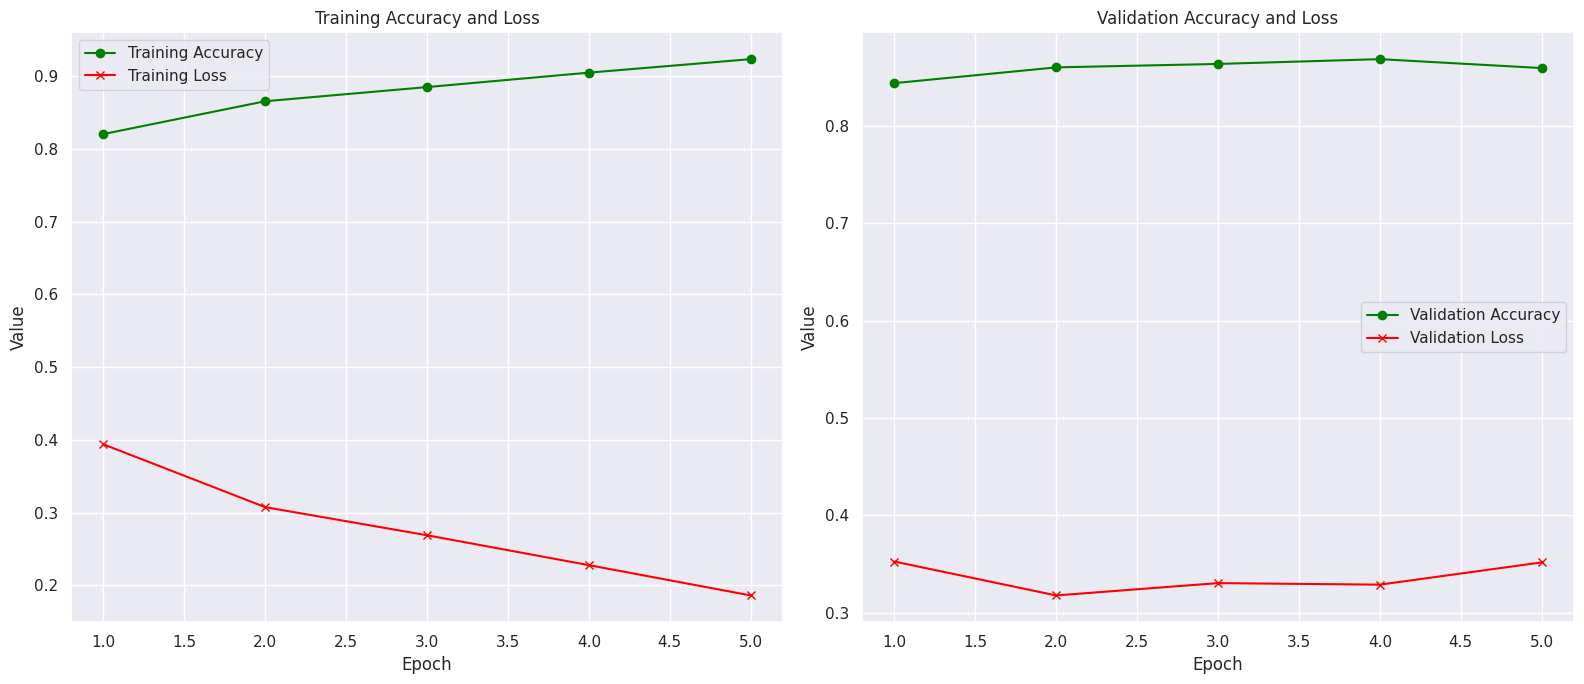

In [168]:
plot_metrics(training_accuracies, training_losses, validation_accuracies, validation_losses)

# testing the model on test dataset

In [197]:
def evaluation(model, dataloader, device):
    model.eval()
    all_preds = []
    all_labels = []

    with torch.no_grad():
        for inputs, labels in dataloader:
            inputs, labels = inputs.to(device), labels.float().to(device)
            logits, _ = model(inputs)
            preds = torch.round(torch.sigmoid(logits)).int()

            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
            
    print("Classification Report:")
    print(classification_report(all_labels, all_preds, target_names=['Not Sarcastic', 'Sarcastic']))
    
    cm = confusion_matrix(all_labels, all_preds)
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt='d', xticklabels=['Not Sarcastic', 'Sarcastic'], yticklabels=['Not Sarcastic', 'Sarcastic'])
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.title("Confusion Matrix")
    plt.show()

## loading the saved model for testing on testdataset

In [199]:
headline_sarcasm_classifier_and_detector.load_state_dict(torch.load('best_model.pt'))

/tmp/ipykernel_71/2986693306.py:1: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  headline_sarcasm_classifier_and_detector.load_state_dict(torch.load('best_model.pt'))


<All keys matched successfully>

Classification Report:
               precision    recall  f1-score   support

Not Sarcastic       0.86      0.89      0.87      1469
    Sarcastic       0.88      0.84      0.86      1373

     accuracy                           0.87      2842
    macro avg       0.87      0.86      0.86      2842
 weighted avg       0.87      0.87      0.87      2842



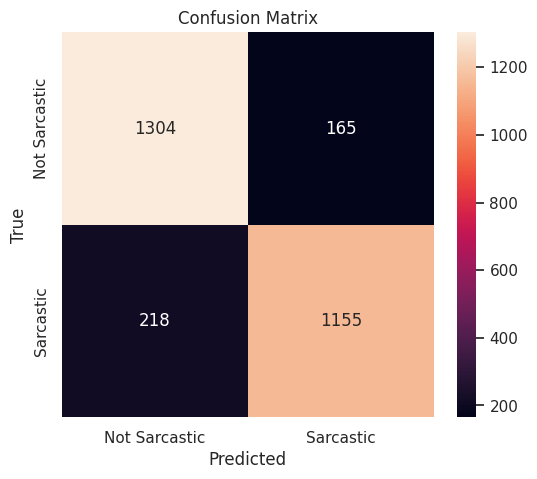

In [200]:
evaluation(headline_sarcasm_classifier_and_detector, test_loader, device)

# preparing a function which takes a text and returns the label (Sarcastic/Non-Sarcastic) & specific words that are making that sentence sarcastic

In [335]:
def get_predicted_class_and_important_words(sentence):
    headline_sarcasm_classifier_and_detector.eval()
    
    cleaned_sentence = clean_text(sentence)
    
    tokenized_sentence = cleaned_sentence.split()
    
    indexed_sentence = tokenized_sentence_to_indexed_sentence(tokenized_sentence)
    
    padded_indexed_sentence = torch.tensor([pad_sequence(indexed_sentence)]).to(device)

    with torch.no_grad():
        logit, attention_weights = headline_sarcasm_classifier_and_detector(padded_indexed_sentence)
        prediction = torch.round(torch.sigmoid(logit))
        attention_weights = attention_weights.squeeze(0).cpu().numpy()
        
    padded_indexed_sentence = padded_indexed_sentence.cpu().numpy().tolist()[0]
    
    considerable_attention_weights = []
    
    for index, weight in zip(padded_indexed_sentence, attention_weights):
        if index != 0:
            considerable_attention_weights.append(weight)
            
    max_weight = torch.max(torch.tensor(considerable_attention_weights))
    
    threshold = 0.5 * max_weight
    
    important_words = [tokenized_sentence[i] for i in range(len(tokenized_sentence)) if considerable_attention_weights[i] >= threshold]
    
    return "Sarcastic" if prediction.item() == 1 else "NOT Sarcastic", important_words

In [336]:
get_predicted_class_and_important_words("Oh great, another Monday. Just what I needed to recharge from the exhausting weekend of doing absolutely nothing.")

('Sarcastic', ['exhausting', 'weekend', 'of', 'doing', 'absolutely'])